In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_percentage_error, r2_score

In [16]:
df = pd.read_csv("energy_usage_plus.csv")
print(df.head())

   temperature  humidity  season  hour district_type  is_weekend  consumption
0         20.0        63  Winter    20    Commercial           0       593.42
1         13.6        68  Summer    23   Residential           0       599.75
2         21.5        94  Summer    14   Residential           0       651.72
3         30.2        80  Autumn    21   Residential           0       658.60
4         12.7        86  Autumn     3   Residential           0       563.55


In [17]:
X = df[['temperature', 'humidity', 'hour', 'is_weekend', 'season', 'district_type']]
y = df['consumption']

categorical_features = ['season', 'district_type']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'
)
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("\nTraining set size:", X_train.shape[0])
print("Test set size:", X_test.shape[0])


Training set size: 800
Test set size: 200


In [24]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mape = mean_absolute_percentage_error(y_test, y_pred)*100
print(f"\nMean Absolute Percentage Error (MAPE): {mape:.2f}%")
r2 = r2_score(y_test, y_pred)
print(f"R² Score: {r2:.4f}")


Mean Absolute Percentage Error (MAPE): 7.52%
R² Score: 0.8378


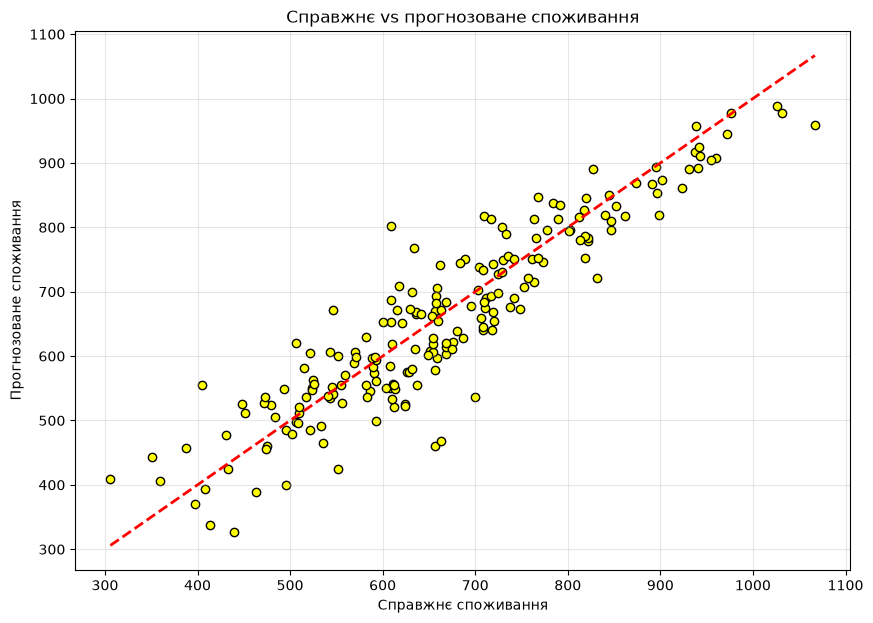

In [29]:
plt.figure(figsize=(10, 7))
plt.scatter(y_test, y_pred, color='yellow', edgecolors='black')

plt.plot( [y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2 )

plt.xlabel("Справжнє споживання")
plt.ylabel("Прогнозоване споживання")
plt.title("Справжнє vs прогнозоване споживання")
plt.grid(alpha=0.3)
plt.show()